# Introdução prática a Machine Learning com scikit-learn

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samuelfsd/intro-ml/blob/main/notebooks/01_introducao_ml.ipynb)

Prever o **salário** de um funcionário a partir de idade, gênero, departamento, experiência e desempenho.

**Fluxo** (**pipeline**): carregar → visualizar → tratar → separar X e y → treino / teste / produção → treinar (`fit`) → prever (`predict`)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils import Bunch
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor

## 1. Carregando o dataset (**data loading**)

Dataset: [maxfactor71/Employee_Performance_Salary](https://huggingface.co/datasets/maxfactor71/Employee_Performance_Salary) (Hugging Face).

A função abaixo lê o CSV e devolve no mesmo formato dos datasets do scikit-learn (`load_iris()`, `load_diabetes()`...).

In [2]:
URL = "https://huggingface.co/datasets/maxfactor71/Employee_Performance_Salary/resolve/main/employee_performance.csv"


def load_salary(url=URL):
    frame = pd.read_csv(url)
    target_names = ["Salary"]
    feature_names = [c for c in frame.columns if c not in target_names]
    return Bunch(
        data=frame[feature_names],
        target=frame["Salary"],
        frame=frame,
        feature_names=feature_names,
        target_names=target_names,
        DESCR="Salário anual (US$) de ~1000 funcionários. Fonte: Hugging Face maxfactor71/Employee_Performance_Salary",
    )


dataset = load_salary()
dataset.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'DESCR'])

In [3]:
print(dataset.DESCR)

Salário anual (US$) de ~1000 funcionários. Fonte: Hugging Face maxfactor71/Employee_Performance_Salary


In [4]:
dataset.feature_names  # entradas (X)

['Employee_ID',
 'Age',
 'Gender',
 'Department',
 'Experience_Years',
 'Performance_Score']

In [5]:
dataset.target_names  # o que queremos prever (y)

['Salary']

In [6]:
dataset.data.head()

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score
0,E0524,49,Female,Operations,5.6,67.8
1,E0603,55,Female,Sales,5.5,NaN
2,E0527,29,Female,Sales,10.7,68.8
3,E0032,30,Female,Operations,9.8,NaN
4,E0617,58,Male,Sales,11.5,72.8


In [7]:
dataset.target.head()

0    33013.0
1    42640.0
2    72180.0
3    65750.0
4    74830.0
Name: Salary, dtype: float64

Para comparar, um dataset que já vem no scikit-learn tem a mesma estrutura:

In [8]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
print(diabetes.keys())
print(diabetes.feature_names)

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


## 2. Visualizando as features (**exploratory data analysis**, EDA)

In [9]:
bruto = dataset.frame
print("Linhas, colunas:", bruto.shape)
bruto.info()

Linhas, colunas: (1020, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   str    
 1   Age                1020 non-null   int64  
 2   Gender             1020 non-null   str    
 3   Department         1020 non-null   str    
 4   Experience_Years   988 non-null    float64
 5   Performance_Score  990 non-null    float64
 6   Salary             1020 non-null   float64
dtypes: float64(3), int64(1), str(3)
memory usage: 55.9 KB


In [10]:
bruto.describe()

,Age,Experience_Years,Performance_Score,Salary
count,1020.000000,988.000000,990.000000,1020.000000
mean,40.898039,7.209919,69.755657,52905.790196
std,11.160063,3.070575,9.935075,33016.717394
min,22.000000,0.000000,37.600000,5000.000000
25%,31.000000,5.200000,63.025000,38867.750000
50%,42.000000,7.250000,70.050000,50595.500000
75%,50.000000,9.200000,76.675000,60984.250000
max,59.000000,16.800000,97.500000,400000.000000


In [11]:
print(bruto["Gender"].value_counts(), "\n")
print(bruto["Department"].value_counts())

Gender
Male      511
Female    509
Name: count, dtype: int64 

Department
Marketing     188
Sales         182
Operations    176
Finance       171
HR            163
IT            140
Name: count, dtype: int64


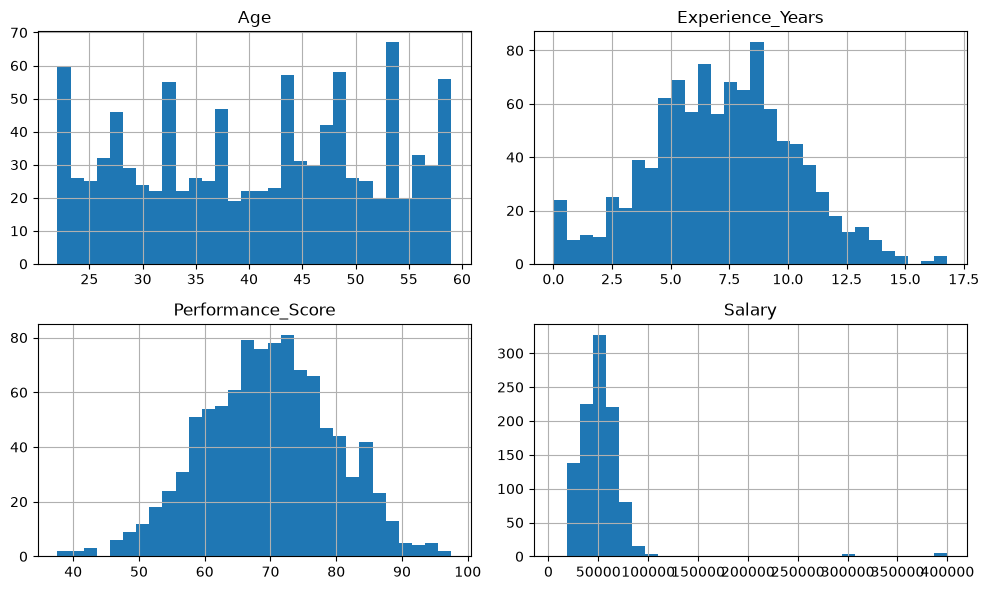

In [12]:
bruto.hist(figsize=(10, 6), bins=30)
plt.tight_layout()
plt.show()

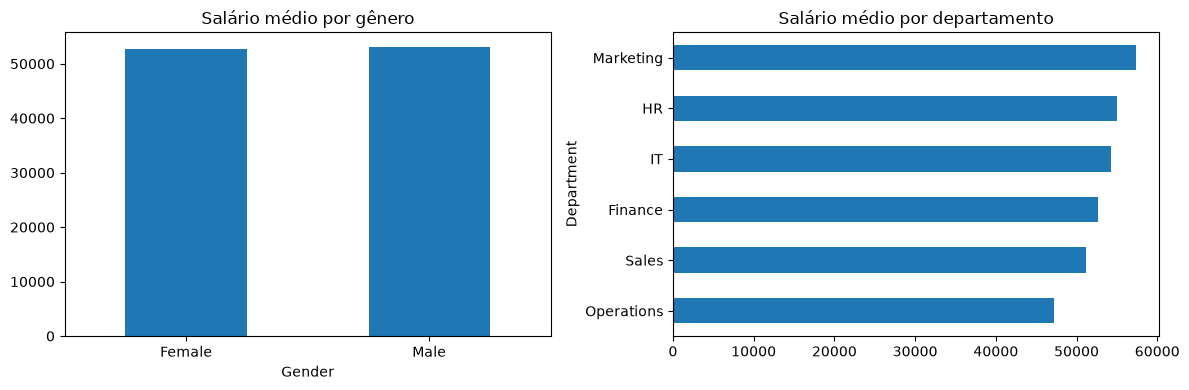

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bruto.groupby("Gender")["Salary"].mean().plot.bar(ax=axes[0], title="Salário médio por gênero", rot=0)
bruto.groupby("Department")["Salary"].mean().sort_values().plot.barh(ax=axes[1], title="Salário médio por departamento")

plt.tight_layout()
plt.show()

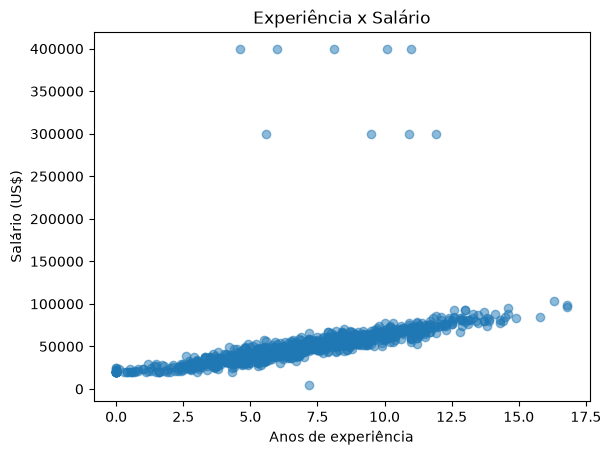

In [14]:
plt.scatter(bruto["Experience_Years"], bruto["Salary"], alpha=0.5)
plt.xlabel("Anos de experiência")
plt.ylabel("Salário (US$)")
plt.title("Experiência x Salário")
plt.show()

## 3. Tratamento dos dados (**data cleaning / preprocessing**)

### 3.1 Remover colunas que não servem para prever (**drop columns**)

In [15]:
df = dataset.frame.drop(columns=["Employee_ID"])  # o tratamento sempre começa dos dados originais
df.head()

,Age,Gender,Department,Experience_Years,Performance_Score,Salary
0,49,Female,Operations,5.6,67.8,33013.0
1,55,Female,Sales,5.5,NaN,42640.0
2,29,Female,Sales,10.7,68.8,72180.0
3,30,Female,Operations,9.8,NaN,65750.0
4,58,Male,Sales,11.5,72.8,74830.0


### 3.2 Linhas duplicadas (**duplicates**)

In [16]:
print("Duplicadas:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape:", df.shape)

Duplicadas: 20
Shape: (1000, 6)


### 3.3 Valores faltando (**missing values**)

In [17]:
print(df.isna().sum(), "\n")
df = df.dropna()
print("Shape:", df.shape)

Age                   0
Gender                0
Department            0
Experience_Years     30
Performance_Score    30
Salary                0
dtype: int64 

Shape: (940, 6)


### 3.4 Valores absurdos (**outliers**)

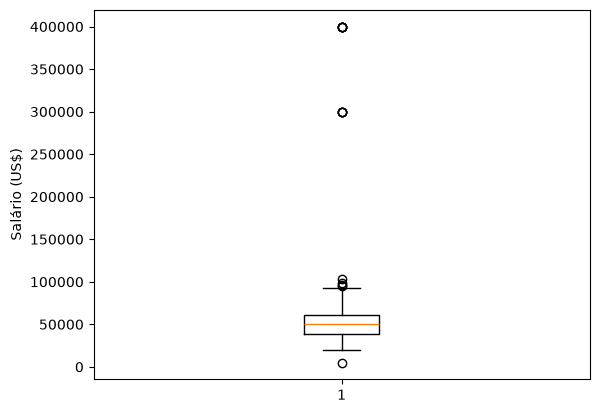

In [18]:
plt.boxplot(df["Salary"])
plt.ylabel("Salário (US$)")
plt.show()

In [19]:
print(df[(df["Salary"] < 10_000) | (df["Salary"] > 200_000)]["Salary"].value_counts(), "\n")

df = df[(df["Salary"] >= 10_000) & (df["Salary"] <= 200_000)]
print("Shape:", df.shape)

Salary
400000.0    5
300000.0    4
5000.0      1
Name: count, dtype: int64 

Shape: (930, 6)


### 3.5 Texto → número (**one-hot encoding**)

In [20]:
df = pd.get_dummies(df, columns=["Gender", "Department"], dtype=int)
df.head()

,Age,Experience_Years,Performance_Score,Salary,Gender_Female,Gender_Male,Department_Finance,Department_HR,Department_IT,Department_Marketing,Department_Operations,Department_Sales
0,49,5.6,67.8,33013.0,1,0,0,0,0,0,1,0
2,29,10.7,68.8,72180.0,1,0,0,0,0,0,0,1
4,58,11.5,72.8,74830.0,0,1,0,0,0,0,0,1
5,46,2.3,73.6,25481.0,1,0,0,0,0,0,0,1
6,56,9.7,85.5,72051.0,0,1,0,0,0,0,0,1


## 4. Separar X (entradas, **features**) e y (alvo, **target**)

In [21]:
X = df.drop(columns=["Salary"])
y = df["Salary"]

print("X:", X.shape)
print("y:", y.shape)

X: (930, 11)
y: (930,)


## 5. Divisão: treino / teste / produção (**train / test split**)

```
 dados tratados
 ┌──────────────────────────────┬──────────┬──────────┐
 │       TREINO (train)         │  TESTE   │ PRODUÇÃO │
 │  o modelo aprende aqui       │  (test)  │ (prod.)  │
 └──────────────────────────────┴──────────┴──────────┘
```

**Produção** (**production**): separamos 5 funcionários e escondemos o salário, simulando dados novos do mundo real.

In [22]:
X_prod = X.sample(5, random_state=0)       # o modelo só vai ver isso
y_prod_escondido = y.loc[X_prod.index]     # guardamos só para conferir no final

X_resto = X.drop(X_prod.index)
y_resto = y.drop(X_prod.index)

X_train, X_test, y_train, y_test = train_test_split(X_resto, y_resto, test_size=0.2, random_state=42)

print("Treino:  ", X_train.shape)
print("Teste:   ", X_test.shape)
print("Produção:", X_prod.shape)

Treino:   (740, 11)
Teste:    (185, 11)
Produção: (5, 11)


## 6. Treinando os modelos (**training**, `fit`)

Todo modelo do scikit-learn segue o mesmo padrão: `modelo.fit(X, y)` para treinar e `modelo.predict(X)` para prever.

### 6.1 Regressão Linear (**Linear Regression**)

In [23]:
linear = LinearRegression()
linear.fit(X_train, y_train)

pd.Series(linear.coef_, index=X.columns).round(0)  # peso de cada feature

Age                         9.0
Experience_Years         4835.0
Performance_Score         208.0
Gender_Female             -48.0
Gender_Male                48.0
Department_Finance        -63.0
Department_HR            -644.0
Department_IT             451.0
Department_Marketing     -262.0
Department_Operations     123.0
Department_Sales          395.0
dtype: float64

### 6.2 Árvore de Decisão (**Decision Tree**)

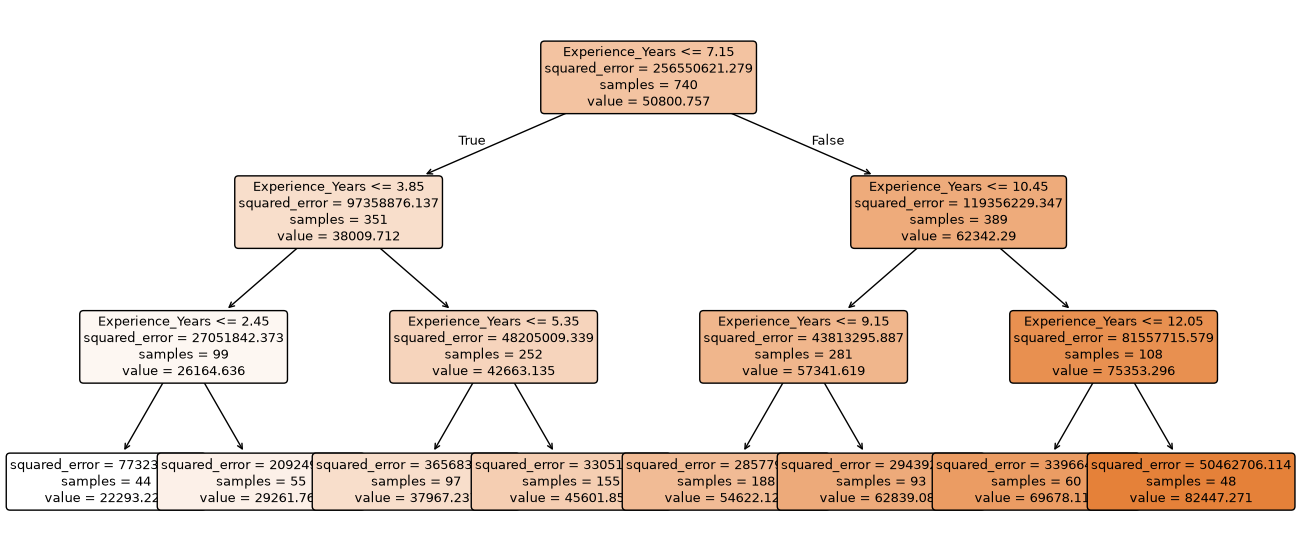

In [24]:
arvore = DecisionTreeRegressor(max_depth=3, random_state=42)
arvore.fit(X_train, y_train)

plt.figure(figsize=(16, 7))
plot_tree(arvore, feature_names=X.columns, filled=True, rounded=True, fontsize=9)
plt.show()

### 6.3 Floresta Aleatória (**Random Forest**)

In [25]:
floresta = RandomForestRegressor(n_estimators=100, random_state=42)
floresta.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## 7. Aplicando nos dados de teste (**prediction / inference**, `predict`)

### 7.1 Uma linha do teste

In [26]:
modelos = {"Linear Regression": linear, "Decision Tree": arvore, "Random Forest": floresta}

linha = X_test.iloc[[0]]
real = y_test.iloc[0]

print(f"{'Real':<20} US$ {real:>8,.0f}")
for nome, modelo in modelos.items():
    previsto = modelo.predict(linha)[0]
    print(f"{nome:<20} US$ {previsto:>8,.0f}   ({previsto - real:+,.0f})")

Real                 US$   50,279
Linear Regression    US$   45,593   (-4,686)
Decision Tree        US$   45,602   (-4,677)
Random Forest        US$   43,848   (-6,431)


### 7.2 Todo o conjunto de teste

In [27]:
comparacao = pd.DataFrame({"real": y_test})
for nome, modelo in modelos.items():
    comparacao[nome] = modelo.predict(X_test)

comparacao.round(0).head(10)

,real,Linear Regression,Decision Tree,Random Forest
356,50279.0,45593.0,45602.0,43848.0
953,20000.0,22222.0,22293.0,22626.0
36,51174.0,48804.0,54622.0,50350.0
909,39412.0,46352.0,45602.0,44708.0
325,64509.0,65686.0,69678.0,65568.0
71,48250.0,48025.0,45602.0,49711.0
236,44925.0,43525.0,45602.0,45225.0
187,68751.0,74466.0,82447.0,78324.0
619,37883.0,36188.0,37967.0,33632.0
968,37492.0,43849.0,45602.0,43458.0


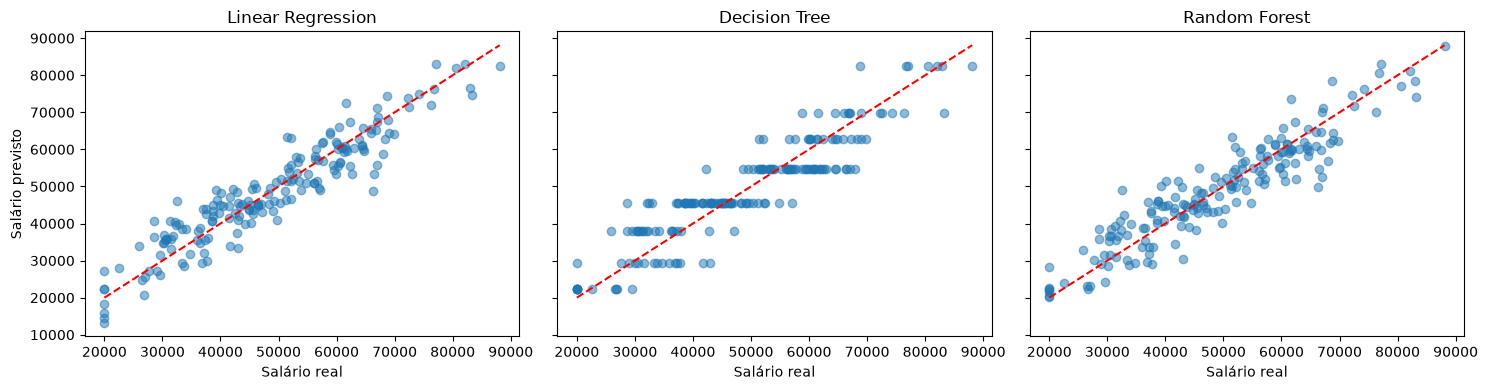

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nome, modelo) in zip(axes, modelos.items()):
    ax.scatter(y_test, modelo.predict(X_test), alpha=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")  # linha do acerto perfeito
    ax.set_title(nome)
    ax.set_xlabel("Salário real")
axes[0].set_ylabel("Salário previsto")
plt.tight_layout()
plt.show()

## 8. Produção (**production / deployment**)

### 8.1 Os 5 funcionários separados (sem salário)

In [29]:
resultado = pd.DataFrame({
    "previsto (random forest)": floresta.predict(X_prod).round(0),
    "real (escondido)": y_prod_escondido,
})
resultado

,previsto (random forest),real (escondido)
483,34319.0,35947.0
830,46886.0,53960.0
370,23181.0,26757.0
528,59003.0,53581.0
281,44935.0,44623.0


### 8.2 Uma pessoa nova (dado bruto → mesmo tratamento → predição)

In [30]:
nova = pd.DataFrame([{"Age": 30, "Gender": "Female", "Department": "IT",
                      "Experience_Years": 5, "Performance_Score": 75}])

nova_tratada = pd.get_dummies(nova, columns=["Gender", "Department"], dtype=int)
nova_tratada = nova_tratada.reindex(columns=X.columns, fill_value=0)

print(f"Salário previsto: US$ {floresta.predict(nova_tratada)[0]:,.0f}")

Salário previsto: US$ 44,674


### 8.3 Salvar e carregar o modelo (**model persistence**)

In [31]:
import joblib

joblib.dump(floresta, "modelo_floresta.joblib")
modelo_carregado = joblib.load("modelo_floresta.joblib")

print(f"Salário previsto: US$ {modelo_carregado.predict(nova_tratada)[0]:,.0f}")

Salário previsto: US$ 44,674


## Exercícios

1. Mude o `random_state` do `train_test_split`. As predições mudam?
2. Mude o `max_depth` da árvore para `1` e para `10`. Como o desenho muda?
3. Na pessoa nova, troque `Gender` para `"Male"`. A predição muda?
4. Remova `Performance_Score` de `X` e treine de novo.
5. Repita todo o fluxo com outro dataset (Hugging Face, Kaggle ou `sklearn.datasets`).

**Próxima leitura:** métricas de avaliação de regressão (**evaluation metrics**: MAE, RMSE, R²).